In [9]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

In [10]:
#importing and cleaning data

df = pd.read_csv("data.csv", dtype={"BB contraindication": str}).fillna(0)
df["BB (0) or CCB (1) or ivabradine (2) or mix (3)"] = df["BB (0) or CCB (1) or ivabradine (2) or mix (3)"].astype(int)
df.head()

df.columns = ["bb_contra", "group", "arrival", "hr_base", "dose_mg", "hr_scan", "scan_time", "nd_segments", "comments"]

#excluding pts who got fluids
df = df[~df["comments"].astype(str).str.contains("fluids", case=False)]

# creatining separate datasets for different rate control agents
df_meto = df[df["group"] == 0].copy()
df_iva  = df[df["group"] == 2].copy()
df_both = df[df["group"] == 3].copy()

In [11]:
# initial single value calculations

# Treat 0 HR as missing so it isn't counted as a real value
df[["hr_base", "hr_scan"]] = df[["hr_base", "hr_scan"]].replace(0, np.nan)

# Rebuild subsets after cleaning
df_meto = df[df["group"] == 0].copy()
df_iva  = df[df["group"] == 2].copy()
df_both = df[df["group"] == 3].copy()

# Flags (asthma = contraindication code contains "2"; suboptimal HR = scan HR >= 65)
for d in (df_meto, df_iva, df_both):
    d["asthma"] = d["bb_contra"].astype(str).str.contains("2")
    d["hr_high"] = d["hr_scan"] >= 65

# 1. Patients per group
print("\n1. Total number of patients per group")
print("Metoprolol only:", len(df_meto))
print("Ivabradine only:", len(df_iva))
print("Both agents:", len(df_both))

# 2. Patients per dose (metoprolol vs ivabradine only)
print("\n2a. Number of patients at each total dose (mg), metoprolol only")
print(df_meto["dose_mg"].value_counts().sort_index())

print("\n2b. Number of patients at each total dose (mg), ivabradine only")
print(df_iva["dose_mg"].value_counts().sort_index())

# 3. Asthma
print("\n3. Number of patients with asthma")
print("Metoprolol only:", int(df_meto["asthma"].sum()))
print("Ivabradine only:", int(df_iva["asthma"].sum()))
print("Both agents:", int(df_both["asthma"].sum()))

# 4. Suboptimal HR
print("\n4. Number of patients with suboptimal HR at scan (>= 65 bpm)")
print("Metoprolol only:", int(df_meto["hr_high"].sum()))
print("Ivabradine only:", int(df_iva["hr_high"].sum()))
print("Both agents:", int(df_both["hr_high"].sum()))


1. Total number of patients per group
Metoprolol only: 129
Ivabradine only: 7
Both agents: 2

2a. Number of patients at each total dose (mg), metoprolol only
0.0       1
50.0     10
58.0      1
75.0     42
100.0    34
125.0     1
150.0    15
175.0     2
200.0    15
225.0     1
300.0     7
Name: dose_mg, dtype: int64

2b. Number of patients at each total dose (mg), ivabradine only
7.5     1
10.0    1
15.0    5
Name: dose_mg, dtype: int64

3. Number of patients with asthma
Metoprolol only: 13
Ivabradine only: 6
Both agents: 1

4. Number of patients with suboptimal HR at scan (>= 65 bpm)
Metoprolol only: 28
Ivabradine only: 5
Both agents: 1


In [19]:
#only keeping metoprolol doses that were frequently used
doses = [50, 75, 100, 150, 200, 300]

def to_minutes(s):
    s = s.astype(str).str.strip().str.replace(r"\.0$", "", regex=True).str.replace(":", "", regex=False)
    s = s.where(~s.isin(["0", "nan", ""]))        # blanks (filled with 0) -> missing
    s = s.str.zfill(4)
    return pd.to_numeric(s.str[:-2], errors="coerce") * 60 + pd.to_numeric(s.str[-2:], errors="coerce")

df["hr_reduction"] = df["hr_base"] - df["hr_scan"]

df["mins_to_scan"] = to_minutes(df["scan_time"]) - to_minutes(df["arrival"])
df.loc[df["mins_to_scan"] < 0, "mins_to_scan"] += 1440   # scan after midnight

df_meto = df[(df["group"] == 0) & (df["dose_mg"].isin(doses))].copy()
df_iva  = df[df["group"] == 2].copy()
df_both = df[df["group"] == 3].copy()

groups = {"Metoprolol only": df_meto, "Ivabradine only": df_iva, "Both agents": df_both}

for label, d in groups.items():
    print(f"\nHR reduction (bpm) by total dose (mg): {label}")
    print(d.groupby("dose_mg")["hr_reduction"].agg(n="count", mean="mean", sd="std").round(1))

print("\nTime from arrival to scan (min), overall")
for label, d in groups.items():
    t = d["mins_to_scan"]
    print(f"{label}: mean = {t.mean():.1f}, SD = {t.std():.1f}, n = {t.count()}")

for label, d in (("Metoprolol only", df_meto), ("Ivabradine only", df_iva)):
    print(f"\nTime from arrival to scan (min) by total dose (mg): {label}")
    print(d.groupby("dose_mg")["mins_to_scan"].agg(n="count", mean="mean", sd="std").round(1))


HR reduction (bpm) by total dose (mg): Metoprolol only
          n  mean    sd
dose_mg                
50.0     10  12.2   7.2
75.0     42  17.0   7.5
100.0    34  20.5   8.4
150.0    15  23.6  17.3
200.0    15  26.5  13.0
300.0     7  25.4  10.4

HR reduction (bpm) by total dose (mg): Ivabradine only
         n  mean    sd
dose_mg               
7.5      1   2.0   NaN
10.0     1  14.0   NaN
15.0     5  16.4  18.0

HR reduction (bpm) by total dose (mg): Both agents
         n  mean   sd
dose_mg              
15.0     2  13.5  9.2

Time from arrival to scan (min), overall
Metoprolol only: mean = 58.8, SD = 28.5, n = 123
Ivabradine only: mean = 85.6, SD = 28.5, n = 7
Both agents: mean = 105.5, SD = 57.3, n = 2

Time from arrival to scan (min) by total dose (mg): Metoprolol only
          n   mean    sd
dose_mg                 
50.0     10   44.0  27.7
75.0     42   46.7  20.3
100.0    34   46.3  17.3
150.0    15   81.5  17.8
200.0    15   86.1  24.1
300.0     7  106.7  26.8

Time from a

In [13]:
from statsmodels.stats.proportion import proportion_confint

TARGET = 65   # at target if hr_scan < TARGET

groups = {"Metoprolol only": df_meto, "Ivabradine only": df_iva, "Both agents": df_both}

rows = []
for label, d in groups.items():
    h = d["hr_scan"].dropna()               # only patients with a recorded scan HR
    k, n = int((h < TARGET).sum()), len(h)
    lo, hi = proportion_confint(k, n, method="wilson")
    rows.append({"group": label, "at_target": k, "n_with_hr": n,
                 "pct": round(k / n * 100, 1),
                 "95% CI": f"{lo*100:.1f} to {hi*100:.1f}"})

print(f"\nProportion with HR at scan < {TARGET} bpm")
print(pd.DataFrame(rows).to_string(index=False))


Proportion with HR at scan < 65 bpm
          group  at_target  n_with_hr  pct       95% CI
Metoprolol only         98        123 79.7 71.7 to 85.8
Ivabradine only          2          7 28.6  8.2 to 64.1
    Both agents          1          2 50.0  9.5 to 90.5


In [14]:
from scipy.stats import mannwhitneyu

def compare(col, label):
    a = df_meto[col].dropna()
    b = df_iva[col].dropna()
    u, p = mannwhitneyu(a, b, alternative="two-sided")
    print(f"\n{label}")
    print(f"Metoprolol: median = {a.median():.1f} (IQR {a.quantile(.25):.1f} to {a.quantile(.75):.1f}), n = {len(a)}")
    print(f"Ivabradine: median = {b.median():.1f} (IQR {b.quantile(.25):.1f} to {b.quantile(.75):.1f}), n = {len(b)}")
    print(f"Mann-Whitney U = {u:.0f}, p = {p:.4f}, P(meto > iva) = {u/(len(a)*len(b)):.2f}")

compare("hr_reduction", "HR reduction (bpm)")
compare("mins_to_scan", "Time from arrival to scan (min)")


HR reduction (bpm)
Metoprolol: median = 19.0 (IQR 13.5 to 26.0), n = 123
Ivabradine: median = 13.0 (IQR 3.5 to 16.0), n = 7
Mann-Whitney U = 614, p = 0.0589, P(meto > iva) = 0.71

Time from arrival to scan (min)
Metoprolol: median = 52.0 (IQR 38.0 to 77.0), n = 123
Ivabradine: median = 79.0 (IQR 69.5 to 92.0), n = 7
Mann-Whitney U = 196, p = 0.0156, P(meto > iva) = 0.23


# random dose response analysis

In [15]:
# analyzying metoprolol responses
import statsmodels.formula.api as smf

m = df_meto.dropna(subset=["hr_reduction", "hr_base", "dose_mg"]).copy()

# 1. Stepwise: mean HR reduction per dose and gain over the previous dose
s = m.groupby("dose_mg")["hr_reduction"].agg(n="count", mean="mean", sd="std")
s["gain_vs_prev_dose"] = s["mean"].diff()
print("\nHR reduction by dose and incremental gain over previous dose")
print(s.round(1))

# 2. Linear model: bpm gained per extra 50 mg, adjusted for baseline HR
m["dose_50mg"] = m["dose_mg"] / 50
lin = smf.ols("hr_reduction ~ dose_50mg + hr_base", m).fit(cov_type="HC3")
print("\nLinear: bpm per additional 50 mg")
print(lin.summary().tables[1])

# 3. Log-dose model: bpm per doubling of dose (captures diminishing returns)
m["log2_dose"] = np.log2(m["dose_mg"])
log = smf.ols("hr_reduction ~ log2_dose + hr_base", m).fit(cov_type="HC3")
print("\nLog-dose: bpm per doubling of dose")
print(log.summary().tables[1])

print("\nAIC linear vs log:", round(lin.aic, 1), round(log.aic, 1))


HR reduction by dose and incremental gain over previous dose
          n  mean    sd  gain_vs_prev_dose
dose_mg                                   
50.0     10  12.2   7.2                NaN
75.0     42  17.0   7.5                4.8
100.0    34  20.5   8.4                3.5
150.0    15  23.6  17.3                3.1
200.0    15  26.5  13.0                2.9
300.0     7  25.4  10.4               -1.1

Linear: bpm per additional 50 mg
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -46.0947      6.505     -7.086      0.000     -58.845     -33.345
dose_50mg     -1.1090      0.598     -1.855      0.064      -2.281       0.063
hr_base        0.8672      0.090      9.637      0.000       0.691       1.044

Log-dose: bpm per doubling of dose
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------

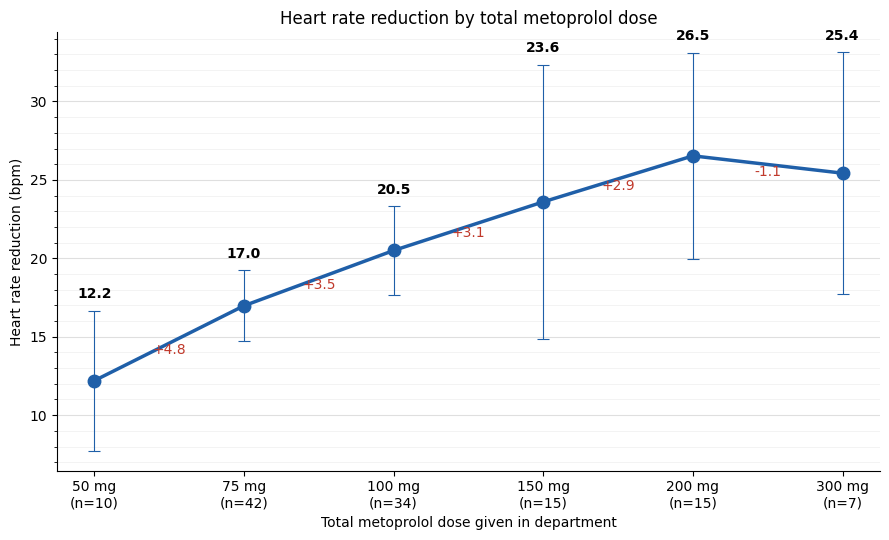

In [16]:
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

s = (df_meto.dropna(subset=["hr_reduction"])
     .groupby("dose_mg")["hr_reduction"]
     .agg(n="count", mean="mean", sd="std"))
s["ci"] = 1.96 * s["sd"] / s["n"] ** 0.5

fig, ax = plt.subplots(figsize=(9, 5.5))
x = range(len(s))

ax.errorbar(x, s["mean"], yerr=s["ci"], fmt="o-", color="#1f5fa8",
            capsize=4, lw=2.5, markersize=9,
            elinewidth=0.8, capthick=0.8)   # thinner error bars

for i, (dose, row) in enumerate(s.iterrows()):
    ax.text(i, row["mean"] + row["ci"] + 0.8, f"{row['mean']:.1f}", ha="center", fontweight="bold")

gains = s["mean"].diff()
for i in range(1, len(s)):
    ax.annotate(f"{gains.iloc[i]:+.1f}", ((i - 0.5), (s["mean"].iloc[i] + s["mean"].iloc[i-1]) / 2),
                ha="center", va="top", color="#c0392b", fontsize=10)

ax.set_xticks(list(x))
ax.set_xticklabels([f"{int(d)} mg\n(n={n})" for d, n in zip(s.index, s["n"])])
ax.set_xlabel("Total metoprolol dose given in department")
ax.set_ylabel("Heart rate reduction (bpm)")
ax.set_title("Heart rate reduction by total metoprolol dose")
ax.spines[["top", "right"]].set_visible(False)

# Major and minor gridlines
ax.yaxis.set_minor_locator(AutoMinorLocator(5))
ax.grid(axis="y", which="major", alpha=0.4, linewidth=0.8)
ax.grid(axis="y", which="minor", alpha=0.2, linewidth=0.5)

plt.tight_layout()
plt.savefig("hr_by_dose.png", dpi=300)
plt.show()